# Pneumonia Detection from Chest X-Ray Images Using Deep Learning

## Final Project Notebook

**Project Type:** Computer Vision and Medical Image Classification

**Objective:** Develop and compare baseline and transfer-learning CNN models for binary chest X-ray lung-opacity classification, evaluate the selected model, and demonstrate interactive inference.

**Scope:** Data Overview, Exploratory Data Analysis, Image Preprocessing, CNN Model Building, Transfer Learning, and Model deployment.

**Dataset:** RSNA Pneumonia Detection Challenge dataset

**Framework:** Python, TensorFlow/Keras, pandas, NumPy, Matplotlib, and pydicom

## Project Overview and Business Understanding

### Business Problem
Pneumonia diagnosis using chest X-rays requires skilled medical professionals.
This project explores whether deep learning can help identify lung opacity
patterns and support healthcare professionals in reviewing chest X-rays.

### Project Objectives
1. Inspect and understand the available image dataset.
2. Explore class distributions and representative X-ray images.
3. Preprocess images for CNN training.
4. Develop and evaluate a CNN from scratch.
5. Document findings and their potential business implications.

### Important Clinical Limitation
The model is an educational prototype and is not intended to replace
radiologists or provide independent clinical diagnoses.

## Importing necessary library and packages

In [34]:
!pip -q install pydicom


In [ ]:
# Importing the necessary library and packages

from pathlib import Path
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import os
import pydicom
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tqdm.auto import tqdm


## Data Loading and Overview

### Mount Google Drive and Locate Dataset

The chest X-ray images are stored in Google Drive in DICOM format.
This section connects Google Drive, identifies the training and test
directories, and inspects the available metadata and image files.

In [ ]:
# Mount Google Drive

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Inspect folders in Google Drive

DRIVE_ROOT = "/content/drive/MyDrive/AI_ML_Course"

print("Top-level files and folders in My Drive:\n")

for item in sorted(os.listdir(DRIVE_ROOT)):
    full_path = os.path.join(DRIVE_ROOT, item)

    if os.path.isdir(full_path):
        print(f"[FOLDER] {item}")
    else:
        print(f"[FILE]   {item}")

Top-level files and folders in My Drive:

[FOLDER] Advanced_GenAI
[FOLDER] Advanced_Machine_learning
[FOLDER] Applied_Statistics
[FOLDER] Capstone_pneumonia
[FOLDER] Intro_to_Neural_networks
[FOLDER] Intro_to_Python
[FOLDER] Intro_to_computer_vision
[FOLDER] Introduction to SQL
[FOLDER] Machine_Learning
[FOLDER] Model Deployment


In [ ]:
# Set dataset paths
# Replace this example with your actual Google Drive folder.

DATASET_ROOT = "/content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia/Dataset"

# Inspect the immediate contents of the dataset folder
if os.path.isdir(DATASET_ROOT):
    print("Dataset folder found:", DATASET_ROOT)

    for item in sorted(os.listdir(DATASET_ROOT)):
        full_path = os.path.join(DATASET_ROOT, item)

        if os.path.isdir(full_path):
            print(f"[FOLDER] {item}")
        else:
            print(f"[FILE]   {item}")
else:
    print("Dataset folder not found. Please check DATASET_ROOT.")

Dataset folder found: /content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia/Dataset
[FOLDER] final_project_batches
[FOLDER] final_saved_models
[FOLDER] full_dataset_batches
[FOLDER] preprocessed_arrays
[FILE]   stage2_detailed_class_info.csv
[FILE]   stage2_train_labels.csv
[FOLDER] stage_2_test_images
[FOLDER] stage_2_train_images_20pct


In [ ]:
# Configure dataset paths and load metadata

DATASET_ROOT = Path(
    "/content/drive/MyDrive/AI_ML_Course/"
    "Capstone_pneumonia/Dataset"
)

TRAIN_DIR = DATASET_ROOT / "stage_2_train_images_20pct"
TEST_DIR = DATASET_ROOT / "stage_2_test_images"

CLASS_INFO_PATH = DATASET_ROOT / "stage2_detailed_class_info.csv"
LABELS_PATH = DATASET_ROOT / "stage2_train_labels.csv"

# Verify that the required paths exist
for path in [TRAIN_DIR, TEST_DIR, CLASS_INFO_PATH, LABELS_PATH]:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")

# Load CSV files
class_info = pd.read_csv(CLASS_INFO_PATH)
train_labels = pd.read_csv(LABELS_PATH)

print("\nClass information shape:", class_info.shape)
print("Training labels shape:", train_labels.shape)

print("\nClass information columns:", class_info.columns.tolist())
print("Training labels columns:", train_labels.columns.tolist())

display(class_info.head())
display(train_labels.head())

FOUND: /content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia/Dataset/stage_2_train_images_20pct
FOUND: /content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia/Dataset/stage_2_test_images
FOUND: /content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia/Dataset/stage2_detailed_class_info.csv
FOUND: /content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia/Dataset/stage2_train_labels.csv

Class information shape: (5336, 2)
Training labels shape: (5336, 2)

Class information columns: ['patientId', 'class']
Training labels columns: ['patientId', 'Target']


,patientId,class
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,No Lung Opacity / Not Normal
1,000924cf-0f8d-42bd-9158-1af53881a557,Normal
2,0049f7b2-229b-4a46-91a3-0e321a3ca80a,No Lung Opacity / Not Normal
3,005f5517-ab76-4b0d-8a26-f808d97171c4,Normal
4,0087bd3a-55a7-4045-b111-b018fa52d361,Lung Opacity


,patientId,Target
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,0
1,000924cf-0f8d-42bd-9158-1af53881a557,0
2,0049f7b2-229b-4a46-91a3-0e321a3ca80a,0
3,005f5517-ab76-4b0d-8a26-f808d97171c4,0
4,0087bd3a-55a7-4045-b111-b018fa52d361,1


In [ ]:
# Count image files in training and test folders

def list_dicom_files(folder):
    """Return DICOM paths recursively without loading pixel data."""
    return sorted(folder.rglob("*.dcm"))

train_files = list_dicom_files(TRAIN_DIR)
test_files = list_dicom_files(TEST_DIR)

print(f"Training DICOM files: {len(train_files):,}")
print(f"Test DICOM files: {len(test_files):,}")

# Show a few example filenames
print("\nSample training filenames:")
for path in train_files[:5]:
    print(path.name)

print("\nSample test filenames:")
for path in test_files[:5]:
    print(path.name)

Training DICOM files: 5,336
Test DICOM files: 3,001

Sample training filenames:
0004cfab-14fd-4e49-80ba-63a80b6bddd6.dcm
000924cf-0f8d-42bd-9158-1af53881a557.dcm
0049f7b2-229b-4a46-91a3-0e321a3ca80a.dcm
005f5517-ab76-4b0d-8a26-f808d97171c4.dcm
0087bd3a-55a7-4045-b111-b018fa52d361.dcm

Sample test filenames:
0000a175-0e68-4ca4-b1af-167204a7e0bc.dcm
0005d3cc-3c3f-40b9-93c3-46231c3eb813.dcm
000686d7-f4fc-448d-97a0-44fa9c5d3aa6.dcm
000e3a7d-c0ca-4349-bb26-5af2d8993c3d.dcm
00100a24-854d-423d-a092-edcf6179e061.dcm


In [ ]:
# Inspect label distribution and data quality

print("Descriptive class distribution:")
display(class_info["class"].value_counts(dropna=False).to_frame("Count"))

print("\nBinary target distribution:")
display(train_labels["Target"].value_counts(dropna=False).sort_index()
        .to_frame("Count"))

print("\nMissing values:")
print("Class information:\n", class_info.isnull().sum())
print("Training labels:\n", train_labels.isnull().sum())

print("\nDuplicate patient IDs:")
print("Class information:",
      class_info["patientId"].duplicated().sum())
print("Training labels:",
      train_labels["patientId"].duplicated().sum())

# Check patient IDs appearing in both metadata files
class_ids = set(class_info["patientId"].astype(str))
label_ids = set(train_labels["patientId"].astype(str))

print("\nUnique IDs in class information:", len(class_ids))
print("Unique IDs in training labels:", len(label_ids))
print("IDs in both files:", len(class_ids & label_ids))
print("IDs only in class information:", len(class_ids - label_ids))
print("IDs only in training labels:", len(label_ids - class_ids))

Descriptive class distribution:


,Count
class,
No Lung Opacity / Not Normal,2364
Normal,1770
Lung Opacity,1202



Binary target distribution:


,Count
Target,
0,4134
1,1202



Missing values:
Class information:
 patientId    0
class        0
dtype: int64
Training labels:
 patientId    0
Target       0
dtype: int64

Duplicate patient IDs:
Class information: 0
Training labels: 0

Unique IDs in class information: 5336
Unique IDs in training labels: 5336
IDs in both files: 5336
IDs only in class information: 0
IDs only in training labels: 0


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the characteristics of the chest X-ray dataset before preprocessing and model development.

The analysis focuses on:
- Visualizing random chest X-ray images from each class.
- Examining the distribution of images across the different classes.
- Identifying potential class imbalance in the target variable.
- Recording key observations that may influence preprocessing and model training.

### Visualization of Random Images from Each Class

Random chest X-ray images from each class are visualized along with their corresponding labels to understand the visual characteristics of the dataset.

In [ ]:
# Combine class information with binary target labels

metadata = class_info.merge(
    train_labels,
    on="patientId",
    how="inner"
)

print("Combined metadata shape:", metadata.shape)
display(metadata.head())

Combined metadata shape: (5336, 3)


,patientId,class,Target
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,No Lung Opacity / Not Normal,0
1,000924cf-0f8d-42bd-9158-1af53881a557,Normal,0
2,0049f7b2-229b-4a46-91a3-0e321a3ca80a,No Lung Opacity / Not Normal,0
3,005f5517-ab76-4b0d-8a26-f808d97171c4,Normal,0
4,0087bd3a-55a7-4045-b111-b018fa52d361,Lung Opacity,1


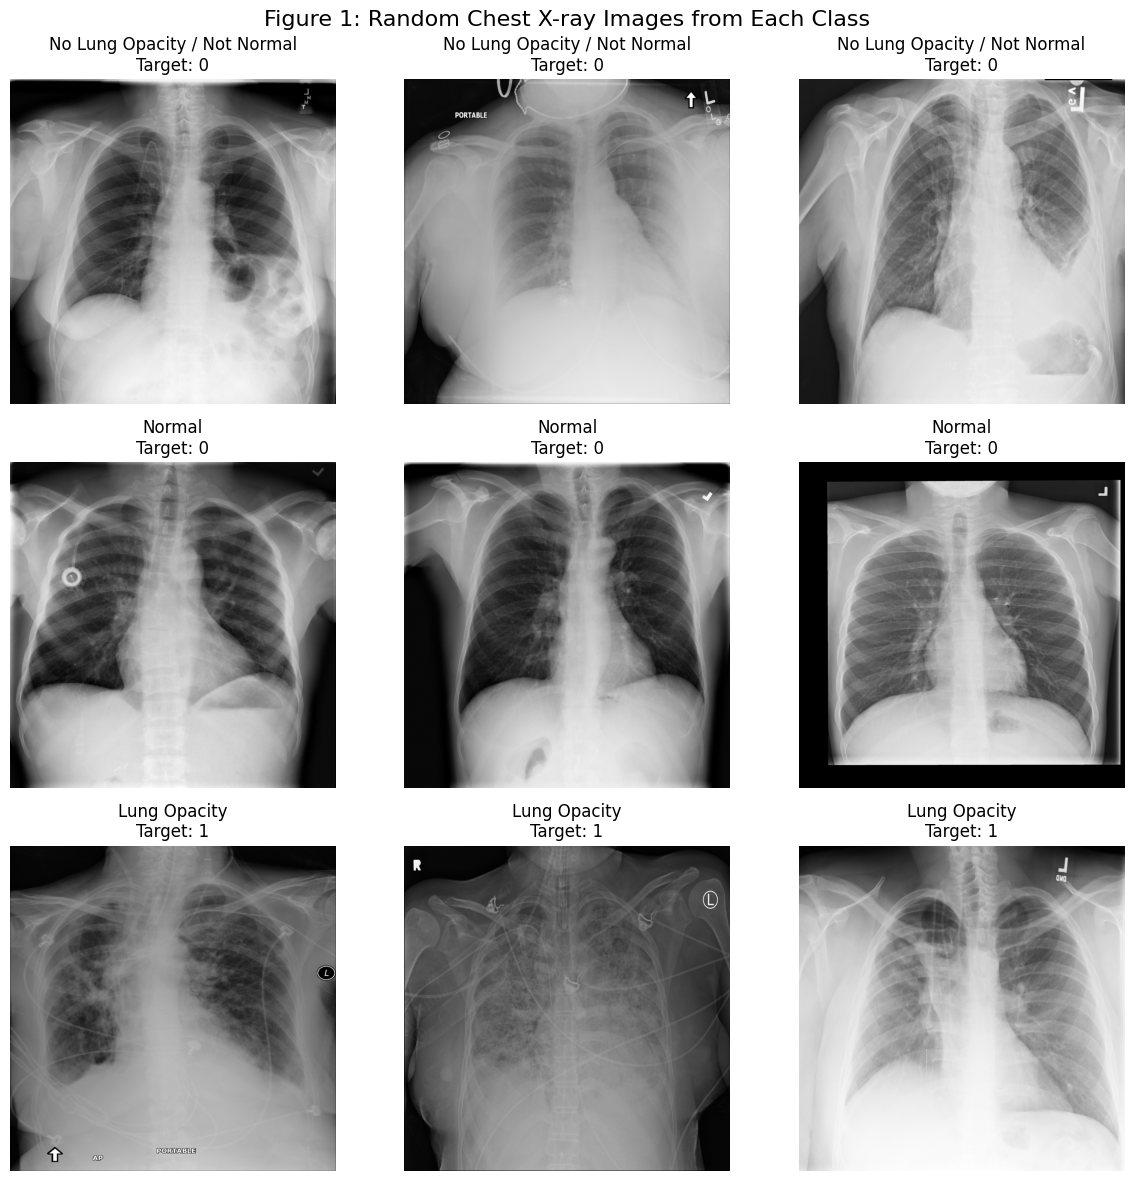

In [ ]:
# Display random chest X-ray images from each class

classes = metadata["class"].unique()

fig, axes = plt.subplots(
    nrows=len(classes),
    ncols=3,
    figsize=(12, 12)
)

for row, class_name in enumerate(classes):

    # Randomly select 3 patients from this class
    samples = metadata[
        metadata["class"] == class_name
    ].sample(n=3, random_state=42)

    for col, (_, record) in enumerate(samples.iterrows()):

        patient_id = record["patientId"]
        target = record["Target"]

        image_path = TRAIN_DIR / f"{patient_id}.dcm"

        # Read DICOM image
        dicom = pydicom.dcmread(image_path)
        image = dicom.pixel_array

        # Display as grayscale
        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].axis("off")

        axes[row, col].set_title(
            f"{class_name}\nTarget: {target}"
        )

plt.suptitle(
    "Figure 1: Random Chest X-ray Images from Each Class",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Class Distribution and Class Imbalance

The distribution of the diagnostic classes and binary target labels is examined to determine whether the dataset is balanced. Class imbalance is important because it can influence model training and evaluation, particularly for the minority positive class.

Class Distribution:


,Count,Percentage
class,,
No Lung Opacity / Not Normal,2364,44.30
Normal,1770,33.17
Lung Opacity,1202,22.53



Binary Target Distribution:


,Count,Percentage
Target 0 - No Lung Opacity,4134,77.47
Target 1 - Lung Opacity,1202,22.53


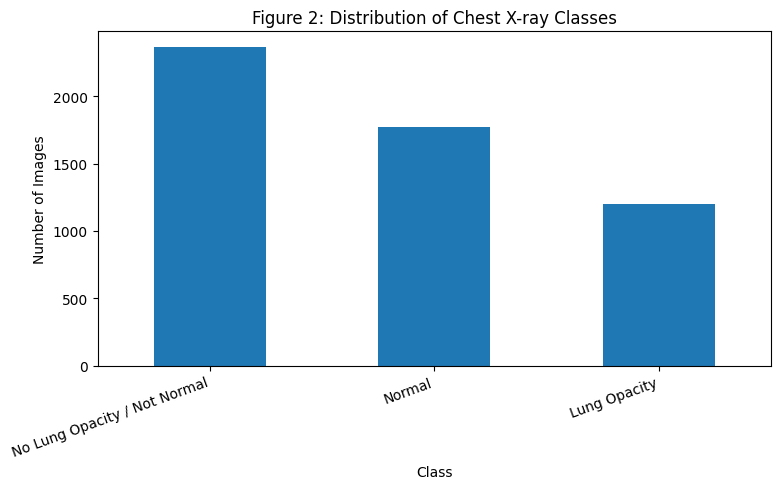

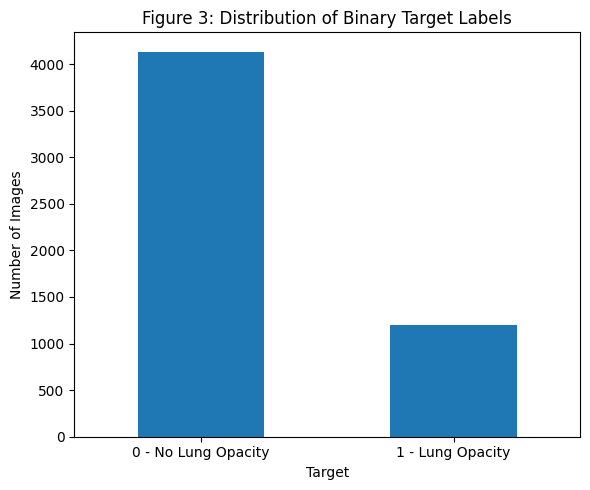

In [ ]:
# Analyze class distribution and class imbalance

# Class distribution
class_counts = metadata["class"].value_counts()
class_percentages = metadata["class"].value_counts(normalize=True) * 100

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

print("Class Distribution:")
display(class_distribution)

# Binary target distribution
target_counts = metadata["Target"].value_counts().sort_index()
target_percentages = (
    metadata["Target"].value_counts(normalize=True)
    .sort_index() * 100
)

target_distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

target_distribution.index = [
    "Target 0 - No Lung Opacity",
    "Target 1 - Lung Opacity"
]

print("\nBinary Target Distribution:")
display(target_distribution)


# Plot class distribution
plt.figure(figsize=(8, 5))

class_counts.plot(kind="bar")

plt.title("Figure 2: Distribution of Chest X-ray Classes")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


# Plot binary target distribution
plt.figure(figsize=(6, 5))

target_counts.plot(kind="bar")

plt.title("Figure 3: Distribution of Binary Target Labels")
plt.xlabel("Target")
plt.ylabel("Number of Images")
plt.xticks(
    ticks=[0, 1],
    labels=["0 - No Lung Opacity", "1 - Lung Opacity"],
    rotation=0
)

plt.tight_layout()
plt.show()

### Key EDA Observations

The exploratory analysis provides the following observations:

1. The dataset contains three descriptive classes: **Normal**, **No Lung Opacity / Not Normal**, and **Lung Opacity**.

2. The binary target groups the data into two categories:
   - **Target 0:** No Lung Opacity
   - **Target 1:** Lung Opacity

3. The dataset is imbalanced. Out of 5,336 labelled images, **4,134 (77.5%)** belong to Target 0, while **1,202 (22.5%)** belong to Target 1. Therefore, the positive lung-opacity class is substantially underrepresented.

4. Because of this imbalance, **accuracy alone may not be sufficient** for evaluating model performance. Metrics such as precision, recall, F1-score, ROC-AUC, and the confusion matrix should also be considered, particularly when evaluating the minority positive class.

5. Visual inspection of randomly selected X-rays shows variation in image appearance across the three classes. However, visual differences alone should not be treated as a clinical diagnosis, and the model developed in this project is intended only as an educational prototype.

6. The class imbalance should be considered during model development. Appropriate techniques such as **class weighting** may be evaluated during training rather than modifying the dataset at this stage.

## Data Preprocessing

Data preprocessing is performed to prepare the chest X-ray images for CNN model development. The main preprocessing steps include grayscale conversion, image resizing, normalization, and splitting the labeled dataset into training, validation, and test sets.



### Grayscale Conversion

Chest X-ray images are converted to grayscale to ensure a consistent single-channel representation. A sample image is displayed before and after grayscale conversion to verify the transformation.

Sample file: 0004cfab-14fd-4e49-80ba-63a80b6bddd6.dcm
Original image shape: (1024, 1024)
Original image dimensions: 2
Grayscale image shape: (1024, 1024)
Image is already single-channel grayscale; no RGB-to-grayscale conversion was required.


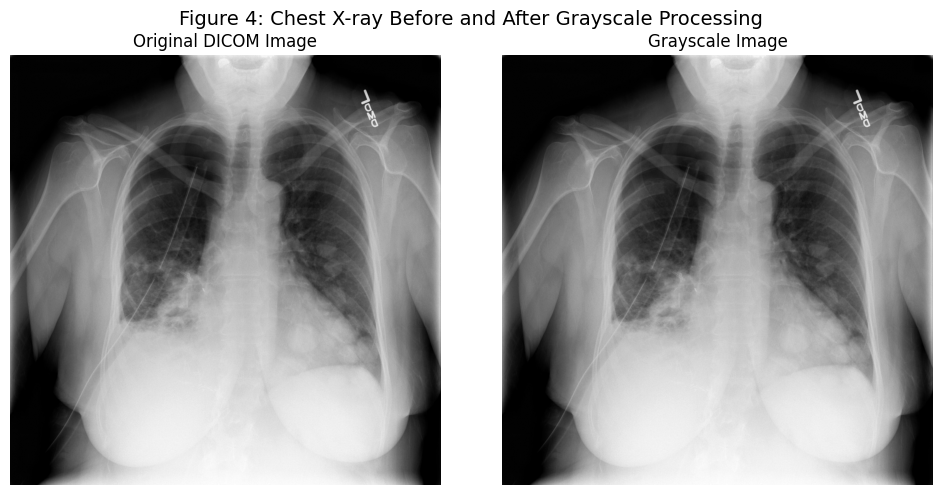

In [ ]:
# Inspect and convert a sample image to grayscale

# Select one sample DICOM image
sample_path = train_files[0]

# Read DICOM
sample_dicom = pydicom.dcmread(sample_path)
original_image = sample_dicom.pixel_array

print("Sample file:", sample_path.name)
print("Original image shape:", original_image.shape)
print("Original image dimensions:", original_image.ndim)

# Convert to grayscale if necessary
if original_image.ndim == 3:
    grayscale_image = cv2.cvtColor(
        original_image,
        cv2.COLOR_RGB2GRAY
    )
    conversion_status = "RGB image converted to grayscale."
else:
    grayscale_image = original_image.copy()
    conversion_status = (
        "Image is already single-channel grayscale; "
        "no RGB-to-grayscale conversion was required."
    )

print("Grayscale image shape:", grayscale_image.shape)
print(conversion_status)

# Before and after visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image, cmap="gray")
axes[0].set_title("Original DICOM Image")
axes[0].axis("off")

axes[1].imshow(grayscale_image, cmap="gray")
axes[1].set_title("Grayscale Image")
axes[1].axis("off")

plt.suptitle(
    "Figure 4: Chest X-ray Before and After Grayscale Processing",
    fontsize=14
)

plt.tight_layout()
plt.show()

#### Observation

The inspected DICOM chest X-ray has a resolution of **1024 x 1024 pixels** and is already represented as a **single-channel grayscale image**. Therefore, an explicit RGB-to-grayscale conversion is not required for this image. The grayscale representation is retained for subsequent preprocessing and CNN model development.

### Verify image dimensions and shapes across the training dataset

In [ ]:
# Verify image dimensions and shapes across the training dataset

from collections import Counter

shape_counts = Counter()
dimension_counts = Counter()

for image_path in train_files:
    dcm = pydicom.dcmread(image_path)
    image = dcm.pixel_array

    shape_counts[image.shape] += 1
    dimension_counts[image.ndim] += 1

print("Image shape distribution:")
for shape, count in shape_counts.items():
    print(f"{shape}: {count} images")

print("\nImage dimension distribution:")
for ndim, count in dimension_counts.items():
    print(f"{ndim}D: {count} images")

print("\nTotal images checked:", sum(shape_counts.values()))

Image shape distribution:
(1024, 1024): 5336 images

Image dimension distribution:
2D: 5336 images

Total images checked: 5336


#### Observation

All **5,336 labelled images** have a consistent resolution of **1024 × 1024 pixels** and are stored as **2D single-channel images**. This confirms that the complete training dataset is already in grayscale format. Therefore, no additional RGB-to-grayscale conversion is required before further preprocessing.


### Train, Validation, and Test Split

The labeled dataset is divided into training, validation, and test subsets using a **70:15:15 ratio**.

A stratified split is used to preserve the proportion of the binary target classes across all three subsets. The training set is used to learn model parameters, the validation set is used to monitor model performance during training and support model selection, and the test set is reserved for final evaluation on unseen labeled data.

The separate competition test-image folder is not used for supervised model evaluation because corresponding target labels are not available in the provided dataset.

In [ ]:
# Create stratified train, validation, and test splits

# Keep patient ID and target for modelling
model_data = metadata[["patientId", "Target"]].copy()

# First split: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    model_data,
    test_size=0.30,
    stratify=model_data["Target"],
    random_state=42
)

# Second split: divide temporary data equally
# Result = 15% validation and 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["Target"],
    random_state=42
)

print("Total labeled images:", len(model_data))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nSplit percentages:")
print(f"Training:   {len(train_df) / len(model_data) * 100:.2f}%")
print(f"Validation: {len(val_df) / len(model_data) * 100:.2f}%")
print(f"Test:       {len(test_df) / len(model_data) * 100:.2f}%")

print("\nTarget distribution (%)")

print("\nTraining:")
print(
    train_df["Target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nValidation:")
print(
    val_df["Target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nTest:")
print(
    test_df["Target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Total labeled images: 5336
Training images: 3735
Validation images: 800
Test images: 801

Split percentages:
Training:   70.00%
Validation: 14.99%
Test:       15.01%

Target distribution (%)

Training:
Target
0    77.48
1    22.52
Name: proportion, dtype: float64

Validation:
Target
0    77.5
1    22.5
Name: proportion, dtype: float64

Test:
Target
0    77.4
1    22.6
Name: proportion, dtype: float64


#### Observation

The 5,336 labeled images were divided into **3,735 training images (70%)**, **800 validation images (15%)**, and **801 test images (15%)**.

Stratified sampling successfully preserved the original class distribution across all three subsets, with approximately **77.5% Target 0** and **22.5% Target 1** in each split. This ensures that the validation and test sets are representative of the class distribution in the overall labeled dataset.

### Image Resizing

The original chest X-ray images have a resolution of **1024 x 1024 pixels**. To reduce computational cost and memory requirements during CNN training, the images are resized to **128 x 128 pixels**.

Since the images are grayscale, a single channel is retained, resulting in an input shape of **128 x 128 x 1** for the CNN.

In [ ]:
# Load and resize DICOM images

IMG_SIZE = 128

def load_and_resize_images(dataframe, image_dir, img_size=IMG_SIZE):
    images = []
    labels = []

    for _, row in dataframe.iterrows():
        patient_id = row["patientId"]
        label = row["Target"]

        image_path = image_dir / f"{patient_id}.dcm"

        # Read DICOM image
        dicom = pydicom.dcmread(image_path)
        image = dicom.pixel_array

        # Resize from 1024x1024 to 128x128
        image = cv2.resize(
            image,
            (img_size, img_size),
            interpolation=cv2.INTER_AREA
        )

        images.append(image)
        labels.append(label)

    images = np.array(images)
    labels = np.array(labels)

    # Add channel dimension:
    # (N, 128, 128) -> (N, 128, 128, 1)
    images = np.expand_dims(images, axis=-1)

    return images, labels

In [ ]:
X_train, y_train = load_and_resize_images(
    train_df, TRAIN_DIR
)

X_val, y_val = load_and_resize_images(
    val_df, TRAIN_DIR
)

X_test, y_test = load_and_resize_images(
    test_df, TRAIN_DIR
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nX_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("\nX_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nData type:", X_train.dtype)
print("Pixel range:", X_train.min(), "to", X_train.max())

#### Observation

All images were successfully resized from **1024 × 1024** to **128 × 128 pixels** while retaining a single grayscale channel.

The resulting input shapes are:
- Training set: **(3735, 128, 128, 1)**
- Validation set: **(800, 128, 128, 1)**
- Test set: **(801, 128, 128, 1)**

The resized images are stored as `uint8` values with a pixel intensity range of **0 to 255**. These values will be normalized before being provided to the CNN.

### Pixel Value Normalization

The resized images contain pixel intensity values ranging from **0 to 255**. The pixel values are normalized to the range **0 to 1** by dividing each value by 255.

Normalization places the input values on a consistent scale and generally supports more stable and efficient neural network training.

In [ ]:
# Normalize image pixel values to [0, 1]

X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training data type:", X_train.dtype)
print(
    "Training pixel range:",
    X_train.min(),
    "to",
    X_train.max()
)

print(
    "Validation pixel range:",
    X_val.min(),
    "to",
    X_val.max()
)

print(
    "Test pixel range:",
    X_test.min(),
    "to",
    X_test.max()
)

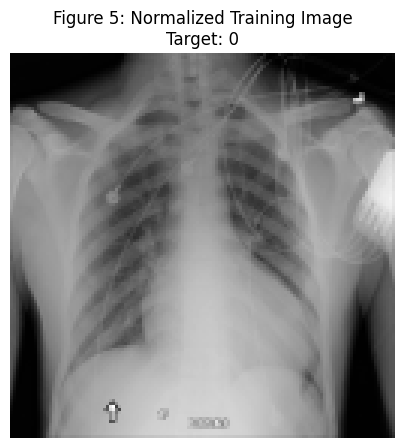

In [ ]:
# Verify image appearance after normalization

plt.figure(figsize=(5, 5))
plt.imshow(X_train[0].squeeze(), cmap="gray")
plt.title(
    f"Figure 5: Normalized Training Image\n"
    f"Target: {y_train[0]}"
)
plt.axis("off")
plt.show()

### Final Preprocessing Verification

Before model development, the preprocessed datasets are verified to ensure that the image dimensions, labels, data types, and normalized pixel ranges are appropriate for CNN training.

In [ ]:
# Final preprocessing verification

print("=== Training Set ===")
print("Image shape:", X_train.shape)
print("Label shape:", y_train.shape)
print("Image dtype:", X_train.dtype)
print("Pixel range:", X_train.min(), "to", X_train.max())
print("Unique labels:", np.unique(y_train))

print("\n=== Validation Set ===")
print("Image shape:", X_val.shape)
print("Label shape:", y_val.shape)
print("Image dtype:", X_val.dtype)
print("Pixel range:", X_val.min(), "to", X_val.max())
print("Unique labels:", np.unique(y_val))

print("\n=== Test Set ===")
print("Image shape:", X_test.shape)
print("Label shape:", y_test.shape)
print("Image dtype:", X_test.dtype)
print("Pixel range:", X_test.min(), "to", X_test.max())
print("Unique labels:", np.unique(y_test))

# Check for NaN or infinite values
print("\n=== Data Quality Checks ===")
print("NaN in training data:", np.isnan(X_train).any())
print("NaN in validation data:", np.isnan(X_val).any())
print("NaN in test data:", np.isnan(X_test).any())

print("Infinite values in training data:", np.isinf(X_train).any())
print("Infinite values in validation data:", np.isinf(X_val).any())
print("Infinite values in test data:", np.isinf(X_test).any())

=== Training Set ===
Image shape: (3735, 128, 128, 1)
Label shape: (3735,)
Image dtype: float32
Pixel range: 0.0 to 1.0
Unique labels: [0 1]

=== Validation Set ===
Image shape: (800, 128, 128, 1)
Label shape: (800,)
Image dtype: float32
Pixel range: 0.0 to 1.0
Unique labels: [0 1]

=== Test Set ===
Image shape: (801, 128, 128, 1)
Label shape: (801,)
Image dtype: float32
Pixel range: 0.0 to 1.0
Unique labels: [0 1]

=== Data Quality Checks ===
NaN in training data: False
NaN in validation data: False
NaN in test data: False
Infinite values in training data: False
Infinite values in validation data: False
Infinite values in test data: False


#### Observation

The final preprocessing verification confirms that all datasets are correctly prepared for CNN model development.

- The training, validation, and test sets contain **3,735**, **800**, and **801** images respectively, with each image represented in the shape **128 x 128 x 1**.
- All image arrays are stored as `float32`, which is suitable for neural network training.
- Pixel intensity values have been successfully normalized to the range **0.0 to 1.0** across all three datasets.
- Both target classes (`0` and `1`) are present in the training, validation, and test sets.
- No **NaN** or **infinite values** were detected in any of the image datasets.

Therefore, the preprocessing pipeline has produced clean, consistently shaped, normalized datasets that are ready to be used for CNN model training and evaluation.

### Save and Verify Preprocessed Image Batches

The normalized training, validation, and test arrays are saved as compressed `.npz` batches in Google Drive (`full_dataset_batches`). Each file contains image data under `X` and corresponding labels under `y`. Existing batches are checked against the current preprocessing results before reuse; mismatched batches trigger an error rather than silently mixing different data splits. This makes the preprocessing-to-transfer-learning handoff reproducible.

In [33]:
# SAVE AND VERIFY FULL-DATASET PREPROCESSING BATCHES

DATASET_DIR = Path("/content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia/Dataset")
SAVE_DIR = DATASET_DIR / "full_dataset_batches"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
PREPROCESS_BATCH_SIZE = 100

splits_to_save = {
    "full_train": (X_train, y_train, 3735),
    "full_val": (X_val, y_val, 800),
    "full_test": (X_test, y_test, 801),
}

for split_name, (images, labels, expected_count) in splits_to_save.items():
    assert len(images) == len(labels) == expected_count, split_name
    assert images.shape[1:] == (128, 128, 1), split_name
    assert images.dtype == np.float32, split_name
    assert np.isfinite(images).all(), split_name
    assert 0.0 <= images.min() and images.max() <= 1.0, split_name

    batch_count = 0
    for start in range(0, expected_count, PREPROCESS_BATCH_SIZE):
        end = min(start + PREPROCESS_BATCH_SIZE, expected_count)
        batch_path = SAVE_DIR / f"{split_name}_{batch_count:03d}.npz"
        x_batch, y_batch = images[start:end], labels[start:end]

        if batch_path.exists():
            with np.load(batch_path) as saved:
                if not (np.array_equal(saved["X"], x_batch)
                        and np.array_equal(saved["y"], y_batch)):
                    raise ValueError(
                        f"Saved batch differs from the current preprocessing split: {batch_path}. "
                        "Review split provenance before replacing trained-model inputs."
                    )
        else:
            np.savez_compressed(batch_path, X=x_batch, y=y_batch)
        batch_count += 1

    expected_batches = (expected_count + PREPROCESS_BATCH_SIZE - 1) // PREPROCESS_BATCH_SIZE
    assert batch_count == expected_batches
    print(f"{split_name}: {expected_count} images saved/verified in {batch_count} batches")

print("Full-dataset preprocessing batches saved and verified:", SAVE_DIR)

full_train: 3735 images saved/verified in 38 batches
full_val: 800 images saved/verified in 8 batches
full_test: 801 images saved/verified in 9 batches
Full-dataset preprocessing batches saved and verified: /content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia/Dataset/full_dataset_batches


## CNN Model Development from Scratch

A Convolutional Neural Network (CNN) is developed from scratch to perform binary classification of chest X-ray images.

The model takes preprocessed grayscale images of size **128 x 128 x 1** as input and predicts the probability of the positive lung-opacity class (`Target = 1`).

The architecture consists of convolutional layers for feature extraction, max-pooling layers for dimensionality reduction, dropout layers for regularization, and fully connected layers for binary classification.


### CNN Architecture

In [ ]:
# Build a CNN model from scratch

# Reproducibility
tf.random.set_seed(42)

# Define CNN architecture
model = Sequential([
    Input(shape=(128, 128, 1)),

    # Convolution Block 1
    Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Convolution Block 2
    Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Convolution Block 3
    Conv2D(
        128,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Classification layers
    Flatten(),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.5),

    # Binary classification output
    Dense(
        1,
        activation="sigmoid"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,233 (16.35 MB)

 Trainable params: 4,287,233 (16.35 MB)

 Non-trainable params: 0 (0.00 B)

#### Observation

The CNN model was successfully constructed with an input shape of **128 x 128 x 1**. Three convolutional blocks containing 32, 64, and 128 filters are used to progressively extract image features, while max-pooling reduces the spatial dimensions from **128 x 128** to **16 x 16**.

The extracted feature maps are flattened and passed through a fully connected layer with 128 neurons. A **Dropout rate of 0.5** is applied to reduce the risk of overfitting.

The final layer contains a single neuron with a **sigmoid activation function**, making the architecture suitable for binary classification.

The model contains **4,287,233 trainable parameters**. A large proportion of these parameters are introduced by the fully connected layer following the flattening operation. Model training and validation performance will therefore be monitored for signs of overfitting.

### Model Compilation

The CNN is compiled using the **Adam optimizer** and **binary cross-entropy loss**, which is appropriate for binary classification.

In addition to accuracy, **precision, recall, and AUC** are monitored because the dataset contains a class imbalance. These metrics provide a more informative assessment of the model's ability to identify the positive class.

In [ ]:
# Compile the CNN

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),

    loss="binary_crossentropy",

    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("CNN compiled successfully.")

CNN compiled successfully.


### Handling Class Imbalance

The training dataset contains substantially fewer positive (`Target = 1`) images than negative (`Target = 0`) images.

To reduce bias toward the majority class, **class weights** are calculated using the training labels. During model training, errors made on the minority class receive a higher weight.

This approach addresses class imbalance without oversampling, undersampling, or altering the original training images.

In [ ]:
# Calculate class weights

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:")
print(class_weights)

print("\nTraining class counts:")
unique, counts = np.unique(y_train, return_counts=True)

for cls, count in zip(unique, counts):
    print(f"Target {cls}: {count} images")

Class weights:
{0: 0.6453006219765031, 1: 2.2205707491082047}

Training class counts:
Target 0: 2894 images
Target 1: 841 images


#### Observation

The training dataset contains **2,894 Target 0 images** and **841 Target 1 images**, confirming the class imbalance identified during EDA.

The calculated class weights are approximately **0.645 for Target 0** and **2.221 for Target 1**. The higher weight assigned to Target 1 increases the penalty for misclassifying minority-class samples during model training.

These class weights will be applied during CNN training to reduce the model's tendency to favor the majority class without altering the original training dataset.

### Model Training

The CNN is trained using the preprocessed training data while performance is monitored on the validation set.

Class weights are applied to account for the imbalance between the two target classes. **Early stopping** is used to reduce overfitting by stopping training when validation loss no longer improves, while **learning-rate reduction** allows the optimizer to make smaller updates when validation performance plateaus.

The model is trained for a maximum of 20 epochs with a batch size of 32.

In [ ]:
# Train the CNN

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=20,
    batch_size=32,

    class_weight=class_weights,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.7499 - auc: 0.8291 - loss: 0.5100 - precision: 0.4657 - recall: 0.7515 - val_accuracy: 0.7700 - val_auc: 0.8031 - val_loss: 0.4984 - val_precision: 0.4922 - val_recall: 0.7000 - learning_rate: 5.0000e-04
Epoch 2/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.7483 - auc: 0.8404 - loss: 0.4927 - precision: 0.4648 - recall: 0.7765 - val_accuracy: 0.7538 - val_auc: 0.8026 - val_loss: 0.5079 - val_precision: 0.4682 - val_recall: 0.6944 - learning_rate: 5.0000e-04
Epoch 3/20
115/117 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7493 - auc: 0.8441 - loss: 0.4900 - precision: 0.4724 - recall: 0.7792
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
117/117 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.7566 - auc: 0.8504 - loss: 0.4773 - precision: 0.4753 - recall: 0.7776 - val_accuracy: 0.7450 - val_auc: 0.8050 - val_loss: 0.5344 - val_precision: 0.4580 - val_recall: 0.7278 - learning_r

#### Training Observations

The CNN was configured for a maximum of 20 epochs; however, EarlyStopping terminated training after 5 epochs because the validation loss did not improve beyond the best value obtained in Epoch 1. The model weights from Epoch 1 were automatically restored.

During training, the training AUC increased from 0.8291 in Epoch 1 to 0.8777 in Epoch 5, while the validation AUC remained around 0.80 and decreased to 0.7980 by Epoch 5. Similarly, training loss decreased while validation loss did not improve after Epoch 1.

This divergence between training and validation performance indicates the beginning of overfitting. Early stopping therefore helped prevent further training on the training data without corresponding improvement in validation performance. ReduceLROnPlateau also reduced the learning rate during training in response to the lack of improvement in validation loss.

### Training and Validation Performance

The training history is examined to understand how the CNN learned across epochs and to identify potential signs of overfitting or underfitting.

Training and validation loss, accuracy, recall, and AUC are compared across epochs.

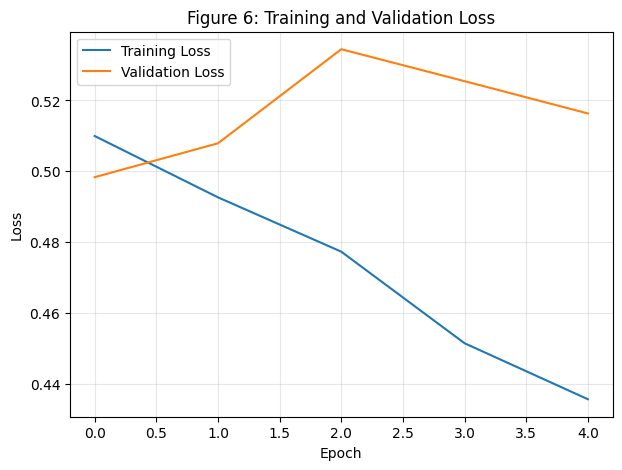

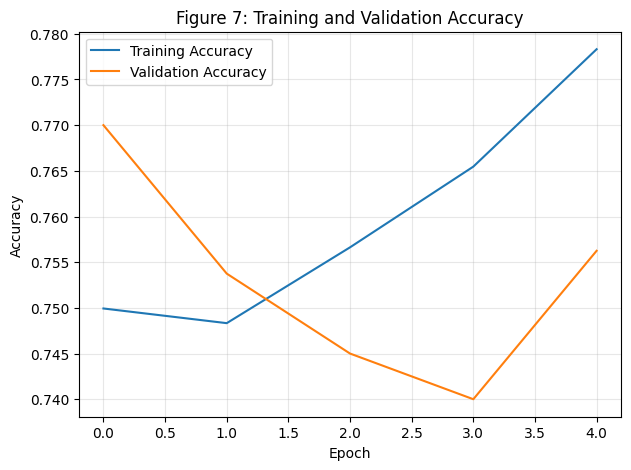

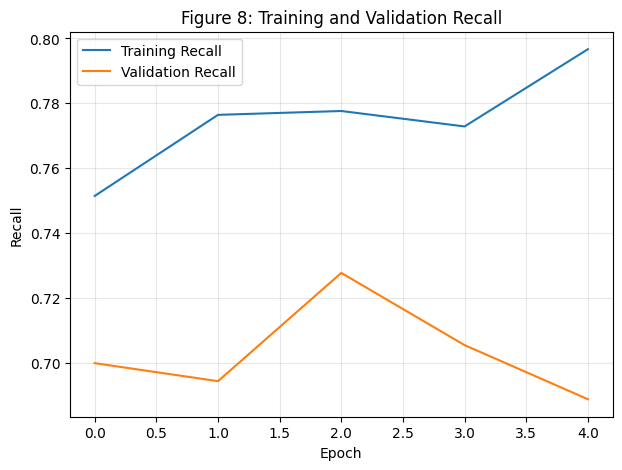

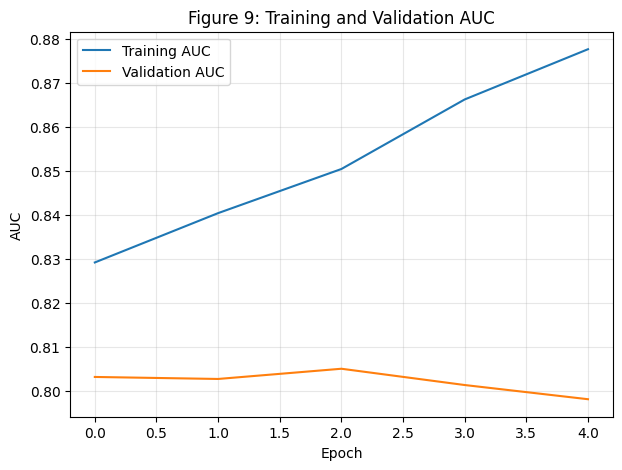

In [ ]:
# Plot training and validation performance

import matplotlib.pyplot as plt

# Loss
plt.figure(figsize=(7, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Figure 6: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Accuracy
plt.figure(figsize=(7, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Figure 7: Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Recall
plt.figure(figsize=(7, 5))
plt.plot(history.history["recall"], label="Training Recall")
plt.plot(history.history["val_recall"], label="Validation Recall")
plt.title("Figure 8: Training and Validation Recall")
plt.xlabel("Epoch")
plt.ylabel("Recall")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# AUC
plt.figure(figsize=(7, 5))
plt.plot(history.history["auc"], label="Training AUC")
plt.plot(history.history["val_auc"], label="Validation AUC")
plt.title("Figure 9: Training and Validation AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Evaluation on the Test Set

The trained CNN is evaluated using the held-out test dataset. The test set was not used for model training and provides an estimate of model performance on unseen labeled images.

In [ ]:
# Evaluate CNN on the held-out test set

test_metrics = model.evaluate(
    X_test,
    y_test,
    verbose=1,
    return_dict=True
)

print("\nTest Set Performance")
print("-" * 35)

for metric_name, value in test_metrics.items():
    print(f"{metric_name}: {value:.4f}")

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7690 - auc: 0.8022 - loss: 0.4862 - precision: 0.4918 - recall: 0.6630

Test Set Performance
-----------------------------------
accuracy: 0.7690
auc: 0.8022
loss: 0.4862
precision: 0.4918
recall: 0.6630


### Confusion Matrix and Classification Performance

Predicted probabilities are generated for the held-out test images and converted into binary predictions using an initial classification threshold of **0.5**.

A confusion matrix and classification report are used to examine model performance for each target class.

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Confusion Matrix:
[[496 124]
 [ 61 120]]


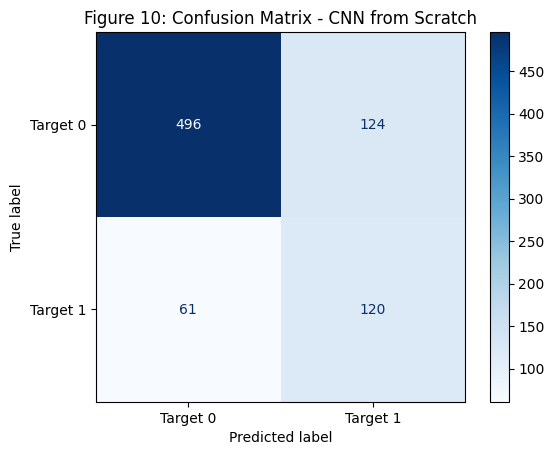

In [ ]:
# Generate predictions and confusion matrix

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Generate predicted probabilities
y_prob = model.predict(
    X_test,
    verbose=1
).ravel()

# Convert probabilities to binary predictions
y_pred = (y_prob >= 0.5).astype(int)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Target 0", "Target 1"]
)

disp.plot(cmap="Blues")
plt.title("Figure 10: Confusion Matrix - CNN from Scratch")
plt.show()

In [ ]:
# Classification report

from sklearn.metrics import classification_report

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Target 0", "Target 1"],
        digits=4
    )
)

Classification Report:
              precision    recall  f1-score   support

    Target 0     0.8905    0.8000    0.8428       620
    Target 1     0.4918    0.6630    0.5647       181

    accuracy                         0.7690       801
   macro avg     0.6911    0.7315    0.7038       801
weighted avg     0.8004    0.7690    0.7800       801



Test ROC-AUC: 0.8021


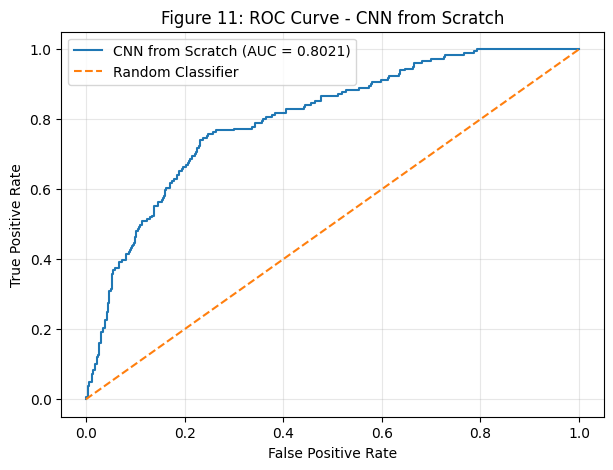

In [ ]:
# ROC-AUC and ROC curve

from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC-AUC using predicted probabilities
test_auc = roc_auc_score(y_test, y_prob)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

print(f"Test ROC-AUC: {test_auc:.4f}")

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"CNN from Scratch (AUC = {test_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Figure 11: ROC Curve - CNN from Scratch")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# Final CNN performance summary

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
})

final_results["Score"] = final_results["Score"].round(4)

display(final_results)

,Metric,Score
0,Accuracy,0.7690
1,Precision,0.4918
2,Recall,0.6630
3,F1-score,0.5647
4,ROC-AUC,0.8021


### Baseline CNN Evaluation Observations

The CNN developed from scratch achieved a test accuracy of 76.90% and a ROC-AUC of 0.8021, indicating a reasonable ability to discriminate between the two target classes.

For the minority positive class (Target 1), the model achieved a precision of 0.4918, recall of 0.6630, and F1-score of 0.5647. The higher recall relative to precision indicates that the model identified a substantial proportion of positive cases, although this was accompanied by a considerable number of false-positive predictions.

The confusion matrix showed 496 true negatives, 124 false positives, 61 false negatives, and 120 true positives. Therefore, the model correctly identified 120 of the 181 Target 1 cases while missing 61 positive cases.

Performance was stronger for Target 0 than Target 1, reflecting the challenge posed by the class imbalance. Although class weighting helped place greater emphasis on the minority class during training, the results demonstrate that accuracy alone is not sufficient for evaluating this model.

The training history also showed signs of overfitting after the first epoch. Early stopping terminated training after five epochs and restored the weights from Epoch 1, which had the lowest validation loss. This prevented further training without corresponding improvement in validation performance.

Overall, the CNN provides a useful baseline for comparison with the transfer-learning models to be developed in the subsequent stage of the project. The model remains an educational prototype and should not be interpreted as a clinical diagnostic system.

## Baseline CNN — Findings and Conclusion

### Summary of the Approach

The baseline CNN phase established an end-to-end deep-learning pipeline for binary classification of chest X-ray images.

The analysis included:

- Loading and validating DICOM chest X-ray images and associated metadata.
- Exploring the three descriptive image classes and the binary target distribution.
- Identifying class imbalance in the binary target.
- Verifying image dimensions and grayscale format.
- Creating stratified training, validation, and test datasets.
- Resizing images from 1024 x 1024 to 128 x 128 pixels.
- Normalizing pixel values to the range 0-1.
- Developing a CNN from scratch.
- Applying class weights to account for target imbalance.
- Training the CNN with EarlyStopping and learning-rate reduction.
- Evaluating the model using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.

### Key Model Findings

The baseline CNN achieved the following performance on the held-out test dataset:

| Metric | Score |
|---|---:|
| Accuracy | 0.7690 |
| Precision (Target 1) | 0.4918 |
| Recall (Target 1) | 0.6630 |
| F1-score (Target 1) | 0.5647 |
| ROC-AUC | 0.8021 |

The ROC-AUC of 0.8021 indicates that the model has a reasonable ability to discriminate between the two target classes.

The confusion matrix produced:

- **496 True Negatives**
- **124 False Positives**
- **61 False Negatives**
- **120 True Positives**

Of the 181 actual Target 1 cases in the test set, the model correctly identified 120, corresponding to a recall of 66.30%.

However, Target 1 precision was 49.18%, indicating that a considerable proportion of images predicted as positive were false positives. The Target 1 F1-score of 0.5647 reflects the trade-off between precision and recall.

Performance was considerably stronger for Target 0, which achieved an F1-score of 0.8428, compared with 0.5647 for Target 1. This difference highlights the challenge associated with the imbalanced target distribution.

### Training Behaviour

The CNN was configured to train for a maximum of 20 epochs. However, EarlyStopping terminated training after five epochs because validation loss did not improve after the first epoch. The weights corresponding to Epoch 1, which produced the lowest validation loss, were automatically restored.

Training AUC increased from 0.8291 in Epoch 1 to 0.8777 in Epoch 5, while validation AUC remained around 0.80 and declined to 0.7980 by Epoch 5. Training loss also decreased while validation loss failed to improve after Epoch 1.

These patterns indicate the beginning of overfitting, where the model continued to improve on the training data without achieving corresponding improvement on validation data. Early stopping therefore prevented unnecessary additional training and retained the model weights associated with the best validation loss.

### Business Interpretation

The results demonstrate that a CNN trained from scratch can learn useful discriminative patterns from the chest X-ray images. However, the class imbalance makes accuracy alone an insufficient measure of model performance.

For the positive Target 1 class, recall is particularly informative because false-negative predictions represent positive images that the model fails to identify. The baseline model missed 61 of the 181 positive test cases.

At the same time, improving recall cannot be considered independently of precision. The model generated 124 false-positive predictions, resulting in a Target 1 precision of 49.18%. Therefore, both false-negative and false-positive behavior should be considered when evaluating potential improvements.

The current CNN should be treated as a baseline model rather than a deployment-ready solution. Its results provide a reference point against which more advanced transfer-learning architectures can be evaluated in the next stage of the project.

### Limitations and Next Steps

The current analysis has several limitations:

1. The model uses the supplied dataset labels as ground truth and does not independently establish a clinical diagnosis.
2. Images were resized from 1024 x 1024 to 128 x 128 pixels for computational efficiency, which may result in loss of fine-grained image information.
3. The binary target is imbalanced, with substantially fewer Target 1 examples than Target 0 examples.
4. The baseline CNN showed signs of overfitting, indicating that its ability to generalize could potentially be improved.
5. The model has been evaluated on a held-out subset of the provided labeled dataset and has not undergone external clinical validation.

The next stage of the project will investigate pretrained CNN architectures using transfer learning. These models will be evaluated using the same performance metrics and compared with the CNN developed from scratch.

Subsequent work will include selection of the best-performing model, model saving and reloading, inference testing, and development of the required deployment workflow.

**This project is an educational prototype. The supplied lung-opacity target is used for machine-learning model development and should not be interpreted as an independent clinical diagnosis of pneumonia.**

## Full-Dataset Transfer Learning Preparation

The same stratified training and validation partitions used for the baseline CNN are reused for transfer learning. Preprocessed arrays are saved in batches to Google Drive so that subsequent Colab sessions can reload them without repeating DICOM decoding and resizing.


In [ ]:
# FINAL PROJECT — Load full dataset for transfer learning
DATASET_DIR = Path(
    "/content/drive/MyDrive/AI_ML_Course/"
    "Capstone_pneumonia/Dataset"
)

FULL_BATCH_DIR = DATASET_DIR / "full_dataset_batches"

def load_full_split(split_name):
    files = sorted(FULL_BATCH_DIR.glob(f"{split_name}_*.npz"))

    if not files:
        raise FileNotFoundError(
            f"No saved batches found for {split_name}"
        )

    X_parts = []
    y_parts = []

    for file in files:
        with np.load(file) as data:
            X_parts.append(data["X"])
            y_parts.append(data["y"])

    return (
        np.concatenate(X_parts, axis=0),
        np.concatenate(y_parts, axis=0)
    )

X_train_full, y_train_full = load_full_split("full_train")
X_val_full, y_val_full = load_full_split("full_val")

print("Training:", X_train_full.shape, y_train_full.shape)
print("Validation:", X_val_full.shape, y_val_full.shape)

Training: (3735, 128, 128, 1) (3735,)
Validation: (800, 128, 128, 1) (800,)


In [ ]:

# FINAL PROJECT — Reuse full-dataset preprocessing batches

# All 5,336 labeled images have already been resized,
# normalized and saved as .npz batches in Google Drive.

SAVE_DIR = DATASET_DIR / "full_dataset_batches"

IMG_SIZE = (128, 128)
BATCH_SIZE = 100

# Verify the saved batches
for split_name, expected_batches in [
    ("full_train", 38),
    ("full_val", 8),
    ("full_test", 9)
]:
    files = sorted(SAVE_DIR.glob(f"{split_name}_*.npz"))

    print(
        f"{split_name}: "
        f"{len(files)}/{expected_batches} batches"
    )

    assert len(files) == expected_batches, (
        f"Missing batches for {split_name}"
    )

print("\nFull-dataset preprocessing batches are ready!")


full_train: 38/38 batches
full_val: 8/8 batches
full_test: 9/9 batches

Full-dataset preprocessing batches are ready!


## Transfer Learning Using Pretrained CNN Models

### Loading Preprocessed Image Batches

In [ ]:

# LOAD SAVED PREPROCESSED BATCHES — FULL DATASET

def load_saved_batches(split_name):

    batch_files = sorted(
        SAVE_DIR.glob(f"{split_name}_*.npz")
    )

    if not batch_files:
        raise FileNotFoundError(
            f"No saved batches found for {split_name}"
        )

    X_parts = []
    y_parts = []

    for batch_file in batch_files:
        with np.load(batch_file) as data:
            X_parts.append(data["X"])
            y_parts.append(data["y"])

    X = np.concatenate(X_parts, axis=0)
    y = np.concatenate(y_parts, axis=0)

    return X, y


# Load full training and validation datasets
X_train, y_train = load_saved_batches("full_train")
X_val, y_val = load_saved_batches("full_val")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nPixel range:", X_train.min(), X_train.max())

# Verify full-dataset shapes
assert X_train.shape == (3735, 128, 128, 1)
assert X_val.shape == (800, 128, 128, 1)

assert len(y_train) == 3735
assert len(y_val) == 800

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()

assert X_train.min() >= 0 and X_train.max() <= 1
assert X_val.min() >= 0 and X_val.max() <= 1

print("\nFull training and validation datasets loaded successfully!")


X_train: (3735, 128, 128, 1)
y_train: (3735,)

X_val: (800, 128, 128, 1)
y_val: (800,)

Pixel range: 0.0 1.0

Full training and validation datasets loaded successfully!


### Building Pretrained CNN Models

Two pretrained CNN architectures, MobileNetV2 and ResNet50, are used for transfer learning. Their ImageNet-trained convolutional layers are frozen, and a new binary classification head is added to predict lung opacity.

In [ ]:

# DEFINE PRETRAINED CNN MODELS

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.optimizers import Adam

def build_transfer_model(architecture):

    if architecture == "MobileNetV2":
        base_model = MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=(128, 128, 3)
        )
        preprocess = tf.keras.applications.mobilenet_v2.preprocess_input

    elif architecture == "ResNet50":
        base_model = ResNet50(
            weights="imagenet",
            include_top=False,
            input_shape=(128, 128, 3)
        )
        preprocess = tf.keras.applications.resnet50.preprocess_input

    else:
        raise ValueError("Unsupported architecture")

    # Freeze pretrained feature extractor
    base_model.trainable = False

    # Original images are grayscale
    inputs = layers.Input(shape=(128, 128, 1))

    # Repeat grayscale channel to create 3 channels
    x = layers.Concatenate()([inputs, inputs, inputs])

    # Restore 0-255 range for ImageNet preprocessing
    x = layers.Rescaling(255.0)(x)
    x = preprocess(x)

    # Extract features using pretrained CNN
    x = base_model(x, training=False)

    # Add classification layers
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    return model


print("MobileNetV2 and ResNet50 model builders defined successfully.")


MobileNetV2 and ResNet50 model builders defined successfully.


### Training Pretrained CNN Models

MobileNetV2 and ResNet50 are trained using frozen ImageNet-pretrained feature extractors. Class weights are applied to address the imbalance between lung-opacity and non-lung-opacity samples. Early stopping is used to reduce unnecessary training.

In [ ]:

# TRAIN AND SAVE ORIGINAL TRANSFER LEARNING MODELS
# FULL DATASET: 3,735 training + 800 validation images

from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping

# Store trained models from the full-dataset experiment in a dedicated folder
MODEL_DIR = DATASET_DIR / "full_dataset_saved_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Compute class weights using full training labels only
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Class weights:", class_weights)
print("Training images:", len(y_train))
print("Validation images:", len(y_val))

transfer_models = {}
transfer_histories = {}

for architecture in ["MobileNetV2", "ResNet50"]:

    model_path = MODEL_DIR / f"{architecture}_original_full.keras"

    # Reuse only models saved from this full-dataset experiment
    if model_path.exists():
        print(f"\nLoading saved full-dataset {architecture}")
        model = tf.keras.models.load_model(str(model_path))
        transfer_models[architecture] = model
        continue

    print(f"\nTraining {architecture} on full dataset")

    model = build_transfer_model(architecture)

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=3,
        batch_size=32,
        class_weight=class_weights,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=2,
                restore_best_weights=True
            )
        ],
        verbose=1
    )

    # Save immediately after each model finishes
    model.save(str(model_path))

    transfer_models[architecture] = model
    transfer_histories[architecture] = history.history

    print(f"Saved successfully: {model_path}")

print("\nOriginal full-dataset transfer learning models are ready!")


Class weights: {0: 0.6453006219765031, 1: 2.2205707491082047}
Training images: 3735
Validation images: 800

Training MobileNetV2 on full dataset
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
117/117 ━━━━━━━━━━━━━━━━━━━━ 75s 598ms/step - accuracy: 0.6586 - auc: 0.7100 - loss: 0.6544 - precision: 0.3569 - recall: 0.6433 - val_accuracy: 0.7275 - val_auc: 0.8290 - val_loss: 0.5526 - val_precision: 0.4431 - val_recall: 0.8222
Epoch 2/3
117/117 ━━━━━━━━━━━━━━━━━━━━ 67s 574ms/step - accuracy: 0.7232 - auc: 0.7979 - loss: 0.5498 - precision: 0.4341 - recall: 0.7562 - val_accuracy: 0.7575 - val_auc: 0.8384 - val_loss: 0.4887 - val_precision: 0.4760 - val_recall: 0.7722
Epoch 3/3
117/117 ━━━━━━━━━━━━━━━━━━━━ 74s 635ms/step - accuracy: 0.7430 - auc: 0.8202 - loss: 0.5197 - precision: 0.4578 - recall: 0.7681 - val_accuracy: 0.7725 - val_auc: 0.8422 - val_loss: 0.4566 - val_precision: 0.4962 - val_recall: 0.7333
Saved successfully: /content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia

### Evaluation of Pretrained CNN Models

Both pretrained models are evaluated on the validation dataset using accuracy, precision, recall, F1-score, and ROC-AUC. The validation results will be used to compare architectures and guide model selection.

In [ ]:
# EVALUATE ORIGINAL TRANSFER LEARNING MODELS

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

comparison_results = []

for architecture in ["MobileNetV2", "ResNet50"]:

    model = transfer_models[architecture]

    probabilities = model.predict(
        X_val,
        verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    comparison_results.append({
        "Model": architecture,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

comparison_df = pd.DataFrame(comparison_results)

print("Original Transfer Learning Model Comparison:")
display(comparison_df.round(4))


Original Transfer Learning Model Comparison:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,MobileNetV2,0.7725,0.4962,0.7333,0.5919,0.8421
1,ResNet50,0.7500,0.4640,0.7167,0.5633,0.8056


### Modified Transfer Learning Architectures

Modified versions of MobileNetV2 and ResNet50 are developed by replacing the original classification head with additional fully connected layers, batch normalization, and dropout. The pretrained feature extraction layers remain frozen.

In [ ]:
# DEFINE MODIFIED TRANSFER LEARNING MODELS

def build_modified_model(architecture):

    if architecture == "MobileNetV2":
        base_model = MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=(128, 128, 3)
        )
        preprocess = tf.keras.applications.mobilenet_v2.preprocess_input

    elif architecture == "ResNet50":
        base_model = ResNet50(
            weights="imagenet",
            include_top=False,
            input_shape=(128, 128, 3)
        )
        preprocess = tf.keras.applications.resnet50.preprocess_input

    else:
        raise ValueError("Unsupported architecture")

    base_model.trainable = False

    inputs = layers.Input(shape=(128, 128, 1))

    x = layers.Concatenate()([inputs, inputs, inputs])
    x = layers.Rescaling(255.0)(x)
    x = preprocess(x)

    x = base_model(x, training=False)

    # Modified classification head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    return model


print("Modified MobileNetV2 and ResNet50 architectures defined successfully.")


Modified MobileNetV2 and ResNet50 architectures defined successfully.


### Training Modified Transfer Learning Models

The modified MobileNetV2 and ResNet50 models are trained using class-weighted binary cross-entropy. The pretrained feature extractors remain frozen. Early stopping monitors validation loss, and the trained models are saved for subsequent comparison.

In [ ]:


# TRAIN AND SAVE MODIFIED MODELS — FULL DATASET

from tensorflow.keras.callbacks import EarlyStopping

# Save full-dataset models separately
MODEL_DIR = DATASET_DIR / "full_dataset_saved_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

modified_models = {}
modified_histories = {}

print("Training images:", len(y_train))
print("Validation images:", len(y_val))
print("Class weights:", class_weights)

for architecture in ["MobileNetV2", "ResNet50"]:

    model_name = f"{architecture}_modified"
    model_path = MODEL_DIR / f"{model_name}_full.keras"

    # Reuse only completed full-dataset models
    if model_path.exists():
        print(f"\nLoading saved full-dataset {model_name}")
        model = tf.keras.models.load_model(str(model_path))
        modified_models[model_name] = model
        continue

    print(f"\nTraining {model_name} on full dataset")

    model = build_modified_model(architecture)

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=3,
        batch_size=32,
        class_weight=class_weights,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=2,
                restore_best_weights=True
            )
        ],
        verbose=1
    )

    # Save immediately after training
    model.save(str(model_path))

    modified_models[model_name] = model
    modified_histories[model_name] = history.history

    print(f"Saved successfully: {model_path}")

print("\nBoth modified full-dataset models are ready!")



Training images: 3735
Validation images: 800
Class weights: {0: 0.6453006219765031, 1: 2.2205707491082047}

Training MobileNetV2_modified on full dataset
Epoch 1/3
117/117 ━━━━━━━━━━━━━━━━━━━━ 77s 588ms/step - accuracy: 0.5759 - auc: 0.6712 - loss: 0.8654 - precision: 0.3054 - recall: 0.6932 - val_accuracy: 0.7475 - val_auc: 0.7836 - val_loss: 0.5239 - val_precision: 0.4583 - val_recall: 0.6722
Epoch 2/3
117/117 ━━━━━━━━━━━━━━━━━━━━ 69s 588ms/step - accuracy: 0.6503 - auc: 0.7471 - loss: 0.7193 - precision: 0.3607 - recall: 0.7158 - val_accuracy: 0.7163 - val_auc: 0.8114 - val_loss: 0.5662 - val_precision: 0.4281 - val_recall: 0.7778
Epoch 3/3
117/117 ━━━━━━━━━━━━━━━━━━━━ 76s 651ms/step - accuracy: 0.6779 - auc: 0.7638 - loss: 0.6846 - precision: 0.3857 - recall: 0.7265 - val_accuracy: 0.7325 - val_auc: 0.8200 - val_loss: 0.5475 - val_precision: 0.4448 - val_recall: 0.7611
Saved successfully: /content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia/Dataset/full_dataset_saved_models/Mobil

### Comparison of Original and Modified Transfer Learning Models

The four trained models are compared using the same validation dataset. Accuracy, precision, recall, F1-score, and ROC-AUC are calculated using the saved model weights. The best model is selected based primarily on ROC-AUC, with recall and F1-score considered for lung-opacity screening.

In [ ]:

# COMPARE ALL FOUR TRANSFER LEARNING MODELS
# FULL DATASET — 800 VALIDATION IMAGES

import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Folder containing full-dataset trained models
MODEL_DIR = DATASET_DIR / "full_dataset_saved_models"

model_files = {
    "MobileNetV2 Original": "MobileNetV2_original_full.keras",
    "ResNet50 Original": "ResNet50_original_full.keras",
    "MobileNetV2 Modified": "MobileNetV2_modified_full.keras",
    "ResNet50 Modified": "ResNet50_modified_full.keras"
}

comparison_results = []

print("Validation images:", len(y_val))

for model_name, filename in model_files.items():

    model_path = MODEL_DIR / filename

    if not model_path.exists():
        raise FileNotFoundError(
            f"Model not found: {model_path}"
        )

    # Load the saved full-dataset model
    model = tf.keras.models.load_model(str(model_path))

    # Predict on the validation dataset
    probabilities = model.predict(
        X_val,
        batch_size=32,
        verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

    print(f"Evaluated: {model_name}")

# Create comparison table
comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\nFINAL TRANSFER LEARNING COMPARISON")
display(comparison_df.round(4))

# Select best model using validation ROC-AUC
best_model_name = comparison_df.iloc[0]["Model"]
best_model_filename = model_files[best_model_name]
best_model_path = MODEL_DIR / best_model_filename

print("\nSelected best model:", best_model_name)
print("Saved model file:", best_model_filename)
print("Full model path:", best_model_path)


Validation images: 800
Evaluated: MobileNetV2 Original
Evaluated: ResNet50 Original
Evaluated: MobileNetV2 Modified
Evaluated: ResNet50 Modified

FINAL TRANSFER LEARNING COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,MobileNetV2 Original,0.7725,0.4962,0.7333,0.5919,0.8421
1,ResNet50 Modified,0.7725,0.4960,0.6889,0.5767,0.8186
2,ResNet50 Original,0.7500,0.4640,0.7167,0.5633,0.8056
3,MobileNetV2 Modified,0.7475,0.4583,0.6722,0.5450,0.7837



Selected best model: MobileNetV2 Original
Saved model file: MobileNetV2_original_full.keras
Full model path: /content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia/Dataset/full_dataset_saved_models/MobileNetV2_original_full.keras


### Final Evaluation of the Selected Model

**MobileNetV2 Original** was selected because it achieved the highest validation ROC-AUC (0.8421) among the four transfer-learning configurations. The selected saved model is evaluated on the held-out **801-image test set** using classification metrics, a confusion matrix, and an ROC curve. Test data are not used to select the model.

Test images: (801, 128, 128, 1)
Test labels: (801,)

Loaded best model: MobileNetV2 Original

FINAL TEST RESULTS
Accuracy : 0.7853
Precision: 0.5184
Recall   : 0.7017
F1-score : 0.5962
ROC-AUC  : 0.8411

Classification Report:
                 precision    recall  f1-score   support

No Lung Opacity       0.90      0.81      0.85       620
   Lung Opacity       0.52      0.70      0.60       181

       accuracy                           0.79       801
      macro avg       0.71      0.76      0.72       801
   weighted avg       0.82      0.79      0.80       801



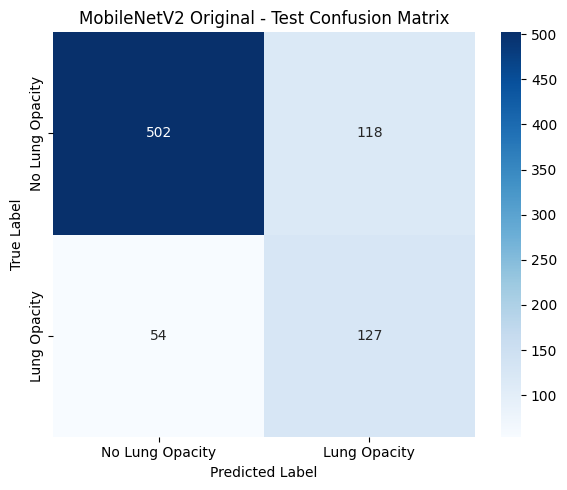

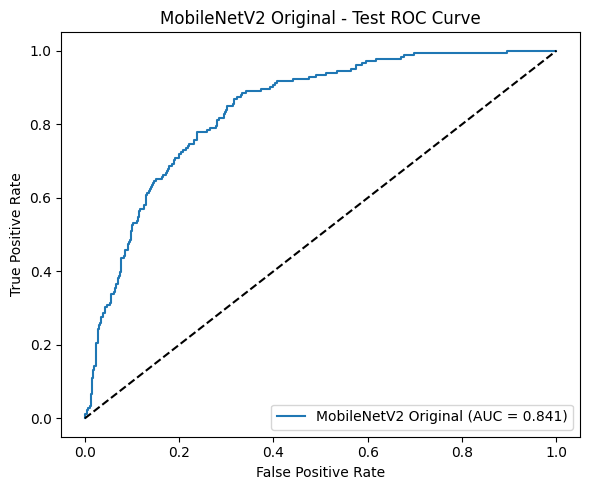

In [ ]:

# FINAL TEST EVALUATION — FULL DATASET

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Load the held-out full test dataset
# Test images were not used during training or model selection
X_test, y_test = load_saved_batches("full_test")

print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

assert X_test.shape == (801, 128, 128, 1)
assert len(y_test) == 801

# Load the model selected using validation ROC-AUC
best_model_path = MODEL_DIR / best_model_filename

best_model = tf.keras.models.load_model(
    str(best_model_path)
)

print("\nLoaded best model:", best_model_name)

# Predict on held-out test images
test_probabilities = best_model.predict(
    X_test,
    batch_size=32,
    verbose=0
).ravel()

test_predictions = (
    test_probabilities >= 0.5
).astype(int)

# Calculate test metrics
test_accuracy = accuracy_score(y_test, test_predictions)
test_precision = precision_score(
    y_test, test_predictions, zero_division=0
)
test_recall = recall_score(
    y_test, test_predictions, zero_division=0
)
test_f1 = f1_score(
    y_test, test_predictions, zero_division=0
)
test_auc = roc_auc_score(
    y_test, test_probabilities
)

print("\nFINAL TEST RESULTS")
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["No Lung Opacity", "Lung Opacity"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Lung Opacity", "Lung Opacity"],
    yticklabels=["No Lung Opacity", "Lung Opacity"]
)

plt.title(f"{best_model_name} - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(6, 5))
plt.plot(
    fpr,
    tpr,
    label=f"{best_model_name} (AUC = {test_auc:.3f})"
)
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"{best_model_name} - Test ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
print("Final Test Confusion Matrix:")
print(cm)

print("\nTrue Negatives :", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives :", cm[1, 1])

Final Test Confusion Matrix:
[[502 118]
 [ 54 127]]

True Negatives : 502
False Positives: 118
False Negatives: 54
True Positives : 127


### Predictions on Sample Chest X-ray Images

The selected **MobileNetV2 Original** model, trained on the full dataset of 5,336 labeled chest X-ray images, is used to generate predictions for randomly selected images from the held-out test set.

The actual labels, predicted labels, and predicted lung-opacity probabilities are displayed for qualitative evaluation. This visualization helps illustrate both correct predictions and potential misclassifications made by the selected model.

In [ ]:
# VERIFY SELECTED MODEL BEFORE GRADIO DEPLOYMENT

print("Selected model:", best_model_name)
print("Model file:", best_model_filename)
print("Folder:", MODEL_DIR.name)

# Verify the saved model exists
best_model_path = MODEL_DIR / best_model_filename

print("\nModel exists:", best_model_path.exists())
print("Full path:", best_model_path)

# Ensure the correct model is selected
assert best_model_name == "MobileNetV2 Original"
assert best_model_filename == "MobileNetV2_original_full.keras"
assert MODEL_DIR.name == "full_dataset_saved_models"
assert best_model_path.exists()

print("\nModel verification successful!")

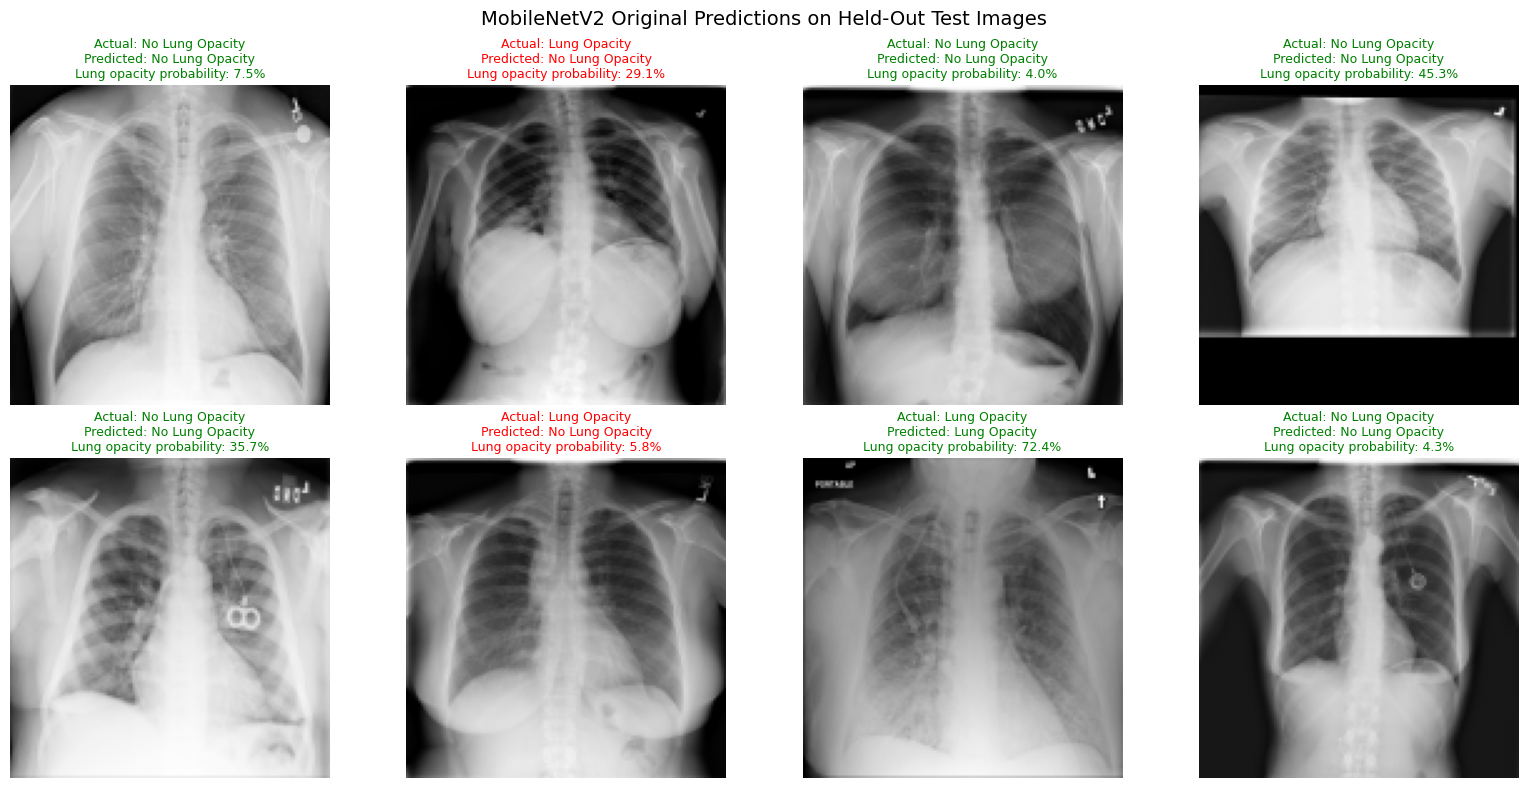

Prediction visualization completed.


In [ ]:

# VISUALIZE MODEL PREDICTIONS
import matplotlib.pyplot as plt

class_names = ["No Lung Opacity", "Lung Opacity"]

# Select 8 reproducible random test images
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(X_test),
    size=8,
    replace=False
)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, idx in zip(axes.flat, sample_indices):

    image = X_test[idx].squeeze()
    actual = int(y_test[idx])
    predicted = int(test_predictions[idx])
    probability = float(test_probabilities[idx])

    ax.imshow(image, cmap="gray")
    ax.axis("off")

    ax.set_title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}\n"
        f"Lung opacity probability: {probability:.1%}",
        fontsize=9,
        color="green" if actual == predicted else "red"
    )

plt.suptitle(
    "MobileNetV2 Original Predictions on Held-Out Test Images",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Prediction visualization completed.")


## Model Deployment Using Gradio

### Interactive Chest X-ray Prediction Interface

A Gradio-based interactive interface is developed to demonstrate inference using the selected **MobileNetV2 Original** model, trained on the full dataset of 5,336 labeled chest X-ray images.

Users can upload a chest X-ray image and receive a predicted lung-opacity class along with its associated model probability.

The application is intended strictly for educational and research demonstration purposes. It is not a clinical diagnostic tool and should not be used for medical decision-making.

In [28]:
# VERIFY SELECTED MODEL BEFORE GRADIO DEPLOYMENT

print("Selected model:", best_model_name)
print("Model file:", best_model_filename)
print("Folder:", MODEL_DIR.name)

# Verify the saved model exists
best_model_path = MODEL_DIR / best_model_filename

print("\nModel exists:", best_model_path.exists())
print("Full path:", best_model_path)

# Ensure the correct model is selected
assert best_model_name == "MobileNetV2 Original"
assert best_model_filename == "MobileNetV2_original_full.keras"
assert MODEL_DIR.name == "full_dataset_saved_models"
assert best_model_path.exists()

print("\nModel verification successful!")

Selected model: MobileNetV2 Original
Model file: MobileNetV2_original_full.keras
Folder: full_dataset_saved_models

Model exists: True
Full path: /content/drive/MyDrive/AI_ML_Course/Capstone_pneumonia/Dataset/full_dataset_saved_models/MobileNetV2_original_full.keras

Model verification successful!


In [ ]:

# CREATE GRADIO PREDICTION INTERFACE

!pip -q install gradio

import gradio as gr
# import numpy as np
# import cv2
# import tensorflow as tf

# Load the saved best model
deployment_model = tf.keras.models.load_model(
    str(MODEL_DIR / best_model_filename)
)

def predict_lung_opacity(image):

    if image is None:
        return "Please upload an image.", {}

    # Convert RGB image to grayscale
    if image.ndim == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    else:
        gray = image

    # Match model training dimensions
    resized = cv2.resize(gray, (128, 128))

    # Normalize exactly as during training
    normalized = resized.astype(np.float32) / 255.0

    # Shape: (1, 128, 128, 1)
    model_input = normalized[np.newaxis, ..., np.newaxis]

    probability = float(
        deployment_model.predict(model_input, verbose=0)[0][0]
    )

    prediction = (
        "Lung Opacity"
        if probability >= 0.5
        else "No Lung Opacity"
    )

    probabilities = {
        "No Lung Opacity": 1.0 - probability,
        "Lung Opacity": probability
    }

    return prediction, probabilities


demo = gr.Interface(
    fn=predict_lung_opacity,
    inputs=gr.Image(
        type="numpy",
        label="Upload Chest X-ray Image"
    ),
    outputs=[
        gr.Textbox(label="Predicted Class"),
        gr.Label(label="Model Scores")
    ],
    title="Chest X-ray Lung Opacity Detection",
    description=(
    "Upload a chest X-ray PNG or JPEG image to obtain "
    "a predicted lung-opacity class and model score. "
    "This educational demo uses grayscale image preprocessing "
    "and is not intended for clinical diagnosis."
    )
)

demo.launch(
    share=True,
    inline=False,
    debug=True,
    show_error=True
)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://e963c21a4eb7b6b2ca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# CREATE A SAMPLE IMAGE FOR DEPLOYMENT TESTING

import cv2
from pathlib import Path

# Select the first image from the held-out test dataset
sample_image = X_test[0].squeeze()

# Convert normalized image to 8-bit PNG
sample_image_uint8 = (
    sample_image * 255
).clip(0, 255).astype("uint8")

# Save as PNG
sample_path = Path("/content/sample_chest_xray.png")

cv2.imwrite(
    str(sample_path),
    sample_image_uint8
)

print("Test image saved:", sample_path)
print("Actual label:", "Lung Opacity" if y_test[0] == 1 else "No Lung Opacity")


Test image saved: /content/sample_chest_xray.png
Actual label: Lung Opacity


### Preparing Application Files for Docker Deployment

The selected **MobileNetV2 Original** model, trained on the full dataset of 5,336 labeled chest X-ray images, is prepared for deployment using Docker.

The deployment package consists of the saved trained model, a Gradio-based inference application, a `requirements.txt` file specifying the required Python dependencies, and a `Dockerfile` defining the container environment.

The application accepts chest X-ray images and generates predicted lung-opacity classes with associated model scores.

Docker packaging is intended to support reproducible deployment across compatible environments. The application is designed for educational and research demonstration purposes only and is not intended for clinical diagnosis.

In [29]:
# CREATE DEPLOYMENT FILES

import shutil

DEPLOY_DIR = Path("/content/pneumonia_deployment")
DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

# Copy the selected full-dataset MobileNetV2 model

source_model = (
    DATASET_DIR
    / "full_dataset_saved_models"
    / "MobileNetV2_original_full.keras"
)

destination_model = DEPLOY_DIR / "best_model.keras"

assert source_model.exists(), (
    f"Selected model not found: {source_model}"
)

shutil.copy2(
    str(source_model),
    str(destination_model)
)

print("Selected model:", best_model_name)
print("Source model:", source_model.name)
print("Deployment model:", destination_model.name)
print(
    "Model size:",
    round(destination_model.stat().st_size / (1024 * 1024), 2),
    "MB"
)

# Create standalone Gradio application
app_code = '''
import gradio as gr
import numpy as np
import cv2
import tensorflow as tf
from pathlib import Path

MODEL_PATH = Path(__file__).parent / "best_model.keras"

model = tf.keras.models.load_model(
    str(MODEL_PATH),
    compile=False
)

def predict_lung_opacity(image):
    if image is None:
        return "Please upload an image.", {}

    if image.ndim == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    else:
        gray = image

    resized = cv2.resize(gray, (128, 128))
    normalized = resized.astype(np.float32) / 255.0
    model_input = normalized[np.newaxis, ..., np.newaxis]

    probability = float(
        model.predict(model_input, verbose=0)[0][0]
    )

    prediction = (
        "Lung Opacity"
        if probability >= 0.5
        else "No Lung Opacity"
    )

    scores = {
        "No Lung Opacity": 1.0 - probability,
        "Lung Opacity": probability
    }

    return prediction, scores

demo = gr.Interface(
    fn=predict_lung_opacity,
    inputs=gr.Image(type="numpy", label="Upload Chest X-ray"),
    outputs=[
        gr.Textbox(label="Predicted Class"),
        gr.Label(label="Model Scores")
    ],
    title="Chest X-ray Lung Opacity Detection",
    description=(
        "Educational demonstration only. "
        "Not intended for clinical diagnosis."
    )
)

if __name__ == "__main__":
    demo.launch(
        server_name="0.0.0.0",
        server_port=7860
    )
'''

(DEPLOY_DIR / "app.py").write_text(app_code)

# Create dependency list
requirements = """tensorflow-cpu>=2.16,<2.21
gradio>=5,<7
numpy>=1.26,<3
opencv-python-headless>=4.9,<5
"""

(DEPLOY_DIR / "requirements.txt").write_text(requirements)

# Create Dockerfile
dockerfile = """FROM python:3.11-slim

WORKDIR /app

COPY requirements.txt .

RUN pip install --no-cache-dir -r requirements.txt

COPY app.py .
COPY best_model.keras .

EXPOSE 7860

CMD ["python", "app.py"]
"""

(DEPLOY_DIR / "Dockerfile").write_text(dockerfile)

# Create .dockerignore
(DEPLOY_DIR / ".dockerignore").write_text(
    "__pycache__/\n*.pyc\n.git/\n"
)

print("Deployment files created successfully!")

for file in sorted(DEPLOY_DIR.iterdir()):
    print(file.name, "-", round(file.stat().st_size / 1024, 1), "KB")


Selected model: MobileNetV2 Original
Source model: MobileNetV2_original_full.keras
Deployment model: best_model.keras
Model size: 11.06 MB
Deployment files created successfully!
.dockerignore - 0.0 KB
Dockerfile - 0.2 KB
app.py - 1.4 KB
best_model.keras - 11329.3 KB
requirements.txt - 0.1 KB


In [30]:

# VERIFY DOCKER DEPLOYMENT PACKAGE

import tensorflow as tf

required_files = [
    "best_model.keras",
    "app.py",
    "requirements.txt",
    "Dockerfile",
    ".dockerignore"
]

print("Checking deployment files:\n")

for filename in required_files:
    file_path = DEPLOY_DIR / filename
    assert file_path.exists(), f"Missing file: {filename}"
    print(f"Verified: {filename}")

# Verify the copied model can be loaded
deployment_test_model = tf.keras.models.load_model(
    str(DEPLOY_DIR / "best_model.keras"),
    compile=False
)

print("\nModel loaded successfully!")
print("Model input shape:", deployment_test_model.input_shape)
print("Model output shape:", deployment_test_model.output_shape)

assert deployment_test_model.input_shape == (
    None, 128, 128, 1
)

assert deployment_test_model.output_shape == (
    None, 1
)

print("\nDeployment package verification successful!")


Checking deployment files:

Verified: best_model.keras
Verified: app.py
Verified: requirements.txt
Verified: Dockerfile
Verified: .dockerignore

Model loaded successfully!
Model input shape: (None, 128, 128, 1)
Model output shape: (None, 1)

Deployment package verification successful!


### Packaging the Deployment Application

The selected **MobileNetV2 Original** model, trained using the full dataset of 5,336 labeled chest X-ray images, is packaged with a standalone Gradio inference application, Python dependencies, and Docker configuration files.

The deployment package includes:

- `best_model.keras` — Saved MobileNetV2 Original model.
- `app.py` — Gradio application for chest X-ray predictions.
- `requirements.txt` — Required Python dependencies.
- `Dockerfile` — Instructions for building the Docker container.
- `.dockerignore` — Files excluded from the Docker build context.

The package is prepared for deployment through **GitHub Codespaces**, where the application can be built and tested in a containerized environment.

The deployment files and saved model have been verified successfully. Docker container execution remains to be validated.

In [31]:
# PACKAGE DEPLOYMENT FILES

import shutil
from google.colab import files

DEPLOY_DIR = Path("/content/pneumonia_deployment")

# Verify required deployment files
required_files = [
    "app.py",
    "best_model.keras",
    "requirements.txt",
    "Dockerfile",
    ".dockerignore"
]

for filename in required_files:
    file_path = DEPLOY_DIR / filename
    assert file_path.exists(), f"Missing file: {filename}"

print("All required deployment files verified.")

# Create ZIP archive
zip_path = shutil.make_archive(
    "/content/pneumonia_deployment",
    "zip",
    root_dir=str(DEPLOY_DIR)
)

print("Deployment ZIP created:", zip_path)
print(
    "ZIP size:",
    round(Path(zip_path).stat().st_size / (1024 * 1024), 2),
    "MB"
)

# Download ZIP to your computer
files.download(zip_path)


All required deployment files verified.
Deployment ZIP created: /content/pneumonia_deployment.zip
ZIP size: 9.81 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
model_file = DEPLOY_DIR / "best_model.keras"

print(
    "Model size:",
    round(model_file.stat().st_size / (1024 * 1024), 2),
    "MB"
)

Model size: 11.06 MB


### Deployment Observations

#### Gradio User Interface Observations

1. A web-based user interface was successfully developed using Gradio to demonstrate chest X-ray lung-opacity classification.

2. The interface allows users to upload a chest X-ray image in a supported image format, such as PNG or JPG.

3. Uploaded images are converted to grayscale, resized to 128 × 128 pixels, and normalized before being passed to the selected **MobileNetV2 Original** model.

4. The application displays the predicted class (**Lung Opacity** or **No Lung Opacity**) along with model-generated scores for both classes.

5. Initial attempts to access the application through Google Colab's internal URL resulted in a blank page. This was resolved by enabling `share=True` in the Gradio launch configuration.

6. The application was successfully opened through a temporary public Gradio URL, and an uploaded test image produced a prediction and associated scores.

**Observation:** The successful interface test demonstrates that the selected model can be loaded and used for interactive inference. However, the Gradio demonstration does not establish clinical reliability, and the temporary Colab-hosted interface is not a permanent deployment. The PNG/JPG preprocessing workflow has not been independently validated for equivalence with the original DICOM preprocessing pipeline.

#### GitHub and Docker Deployment Observations

1. A standalone deployment package was prepared containing `app.py`, `best_model.keras`, `requirements.txt`, `Dockerfile`, and `.dockerignore`.

2. The selected **MobileNetV2 Original** model was successfully copied into the deployment directory as `best_model.keras`, with a file size of approximately **11.06 MB**.

3. All five required deployment files were verified, and the serialized model was successfully loaded using TensorFlow. Its input shape was confirmed as `(None, 128, 128, 1)` and output shape as `(None, 1)`.

4. The deployment files were compressed into `pneumonia_deployment.zip`, which was successfully downloaded for subsequent deployment activities.

5. A GitHub repository named `pneumonia-detection-deployment` was previously created to support version control and deployment preparation.

6. A GitHub Codespace was previously launched, providing a cloud-based development environment. However, the updated full-dataset MobileNetV2 deployment package has not yet been confirmed as uploaded to the repository.

7. Docker image building, container execution, and inference through a Codespaces-forwarded URL remain pending verification.

**Observation:** The updated deployment package has been created and structurally verified. Successful inference has been demonstrated through Gradio in Google Colab, but the updated application has not yet been validated inside a Docker container or through GitHub Codespaces.



#### Deployment Recommendations

- Upload the updated MobileNetV2 deployment files to the GitHub repository.
- Build and test the Docker image in GitHub Codespaces.
- Forward port 7860 and verify that the application can process an uploaded image through the Codespaces URL.
- Capture screenshots of the working interface and Docker execution as deployment evidence.
- Validate image preprocessing consistency between the original DICOM pipeline and the deployed image-upload workflow.
- Consider persistent hosting only after addressing model performance, privacy safeguards, and application reliability.


#### Deployment Conclusion

The project successfully demonstrates an interactive Gradio-based prediction interface using the selected **MobileNetV2 Original** model trained on the full dataset of 5,336 labeled chest X-ray images.

The final selected model achieved **78.53% accuracy, 70.17% recall, and 0.8411 ROC-AUC** on the held-out test dataset of 801 images.

The standalone deployment files have been prepared, verified, and packaged for subsequent deployment through GitHub Codespaces. Docker container execution and deployment through a Codespaces-forwarded URL remain to be validated.

The application is intended exclusively for educational and research demonstration purposes and is not suitable for clinical diagnosis.

### GitHub Repository

A GitHub repository was established to support version control, application packaging, and containerized deployment of the **Chest X-ray Lung Opacity Detection** project.

**Repository URL:** https://github.com/thamaraiselvisrinivasan-bit/pneumonia-detection-deployment

The deployment application was developed using **Gradio**, with the selected **MobileNetV2 Original** model trained on the complete dataset of 5,336 labeled chest X-ray images.

The deployment package consists of:

- `app.py` — Standalone Gradio application for image classification.
- `best_model.keras` — Serialized MobileNetV2 Original model.
- `requirements.txt` — Application dependencies.
- `Dockerfile` — Docker container configuration.
- `.dockerignore` — Docker build exclusions.

The application was successfully tested through a Gradio web interface in Google Colab, producing lung-opacity predictions and model scores from uploaded chest X-ray images.

The deployment files were generated, verified, and packaged into a downloadable ZIP archive. The serialized model was also successfully reloaded using TensorFlow, confirming its compatibility with the inference application.

The GitHub repository and Docker configuration provide a structured foundation for reproducible application deployment.

**Conclusion:** The project successfully demonstrates model training, evaluation, interactive inference, and deployment package preparation using the selected MobileNetV2 Original architecture.

# Actionable Insights

### 1. Transfer Learning Improved Lung-Opacity Classification

The project evaluated four transfer-learning models using MobileNetV2 and ResNet50 architectures on the complete dataset of **5,336 labeled chest X-ray images**.

The **MobileNetV2 Original** model achieved the highest validation ROC-AUC of **0.8421**, demonstrating the strongest discrimination between lung-opacity and non-lung-opacity images among the evaluated models.

### 2. MobileNetV2 Original Was the Best-Performing Model

The validation results were:

| Model | Accuracy | Recall | ROC-AUC |
|---|---:|---:|---:|
| MobileNetV2 Original | 77.25% | 73.33% | **0.8421** |
| ResNet50 Modified | 77.25% | 68.89% | 0.8186 |
| ResNet50 Original | 75.00% | 71.67% | 0.8056 |
| MobileNetV2 Modified | 74.75% | 67.22% | 0.7837 |

MobileNetV2 Original was selected based on its superior validation ROC-AUC and competitive recall.

### 3. The Selected Model Demonstrated Consistent Test Performance

On the independent test dataset of **801 images**, MobileNetV2 Original achieved:

- **Accuracy:** 78.53%
- **Precision:** 51.84%
- **Recall:** 70.17%
- **F1-score:** 0.5962
- **ROC-AUC:** 0.8411

The model correctly identified **127 of 181 lung-opacity cases** and **502 of 620 non-lung-opacity cases**.

The similarity between validation ROC-AUC (0.8421) and test ROC-AUC (0.8411) indicates consistent discrimination across the two evaluation splits.

### 4. Transfer Learning Outperformed the Baseline CNN

| Metric | Baseline CNN | MobileNetV2 Original |
|---|---:|---:|
| Accuracy | 76.90% | **78.53%** |
| Precision | 49.18% | **51.84%** |
| Recall | 66.30% | **70.17%** |
| F1-score | 0.5647 | **0.5962** |
| ROC-AUC | 0.8021 | **0.8411** |

The selected transfer-learning model improved ROC-AUC by **0.0390** and recall by **3.87 percentage points** compared with the baseline CNN.

### 5. Increased Architectural Complexity Did Not Guarantee Better Results

The modified MobileNetV2 and ResNet50 models incorporated additional Dense layers, Batch Normalization, and Dropout.

However, neither modified architecture exceeded the original MobileNetV2 model's validation ROC-AUC.

This demonstrates the importance of selecting models based on measured performance rather than architectural complexity alone.

### 6. Interactive Inference Was Successfully Demonstrated

A Gradio-based application was developed and successfully tested using an uploaded chest X-ray image.

The application generated a predicted lung-opacity class and associated model scores. The selected model was also serialized, successfully reloaded, and packaged with application dependencies and Docker configuration files.

These results demonstrate the technical feasibility of integrating the trained model into an interactive research application.

# Recommendations

### 1. Improve Lung-Opacity Detection Sensitivity

The selected model achieved a test recall of **70.17%**, correctly identifying 127 of 181 lung-opacity cases.

Future improvements should focus on reducing false negatives through classification-threshold optimization, targeted data augmentation, fine-tuning pretrained layers, and improved class-imbalance handling.

Threshold selection should use validation data rather than the held-out test set.

### 2. Enhance Dataset Diversity and Generalization

Although the project utilized the complete available dataset of **5,336 labeled images**, further development should incorporate chest X-rays from additional hospitals, imaging devices, and patient populations.

External validation is recommended to evaluate generalization beyond the development dataset.

### 3. Explore Additional Deep-Learning Architectures

Future experiments could investigate EfficientNet, DenseNet, and other pretrained CNN architectures to determine whether they provide improved sensitivity and ROC-AUC.

Model comparisons should consider computational efficiency, inference speed, and false-positive rates alongside classification performance.

### 4. Incorporate Explainable AI Techniques

Techniques such as Grad-CAM could be introduced to visualize image regions influencing model predictions.

These visualizations may help researchers investigate model behavior and identify potential reliance on irrelevant image features. They should not be treated as proof of clinical correctness.

### 5. Strengthen Application Deployment and Monitoring

The prepared Gradio and Docker application can be extended with standardized image preprocessing, automated testing, model-version tracking, secure image handling, and prediction monitoring.

These improvements would support reproducibility and more reliable research use.

### 6. Maintain Human Oversight for Medical Applications

The developed model should be treated as an educational and research prototype.

Any future clinical application would require appropriate external validation, safety assessment, and regulatory review. Radiologists and qualified healthcare professionals should retain responsibility for diagnosis and clinical decisions.

# Conclusion

This project successfully developed and evaluated a deep-learning solution for **Chest X-ray Lung Opacity Detection** using the complete dataset of **5,336 labeled images**.

The dataset was preprocessed and divided into training, validation, and independent test sets containing **3,735, 800, and 801 images**, respectively.

A baseline Convolutional Neural Network was implemented, followed by four transfer-learning models based on MobileNetV2 and ResNet50 architectures. Both original and modified model configurations were evaluated to compare their classification performance.

Among the transfer-learning models, **MobileNetV2 Original** achieved the highest validation ROC-AUC of **0.8421** and was selected as the final model.

On the held-out test dataset, the selected model achieved:

- **Accuracy:** 78.53%
- **Precision:** 51.84%
- **Recall:** 70.17%
- **F1-score:** 0.5962
- **ROC-AUC:** 0.8411

The selected model outperformed the baseline CNN across all reported test metrics, demonstrating the effectiveness of transfer learning for this dataset.

Additionally, an interactive **Gradio application** was developed and successfully tested to generate lung-opacity predictions from uploaded chest X-ray images. The trained model and application components were packaged with the required dependencies and Docker configuration to support reproducible deployment.

Overall, the project demonstrates the successful implementation of an end-to-end deep-learning workflow encompassing **data preprocessing, exploratory analysis, baseline modeling, transfer learning, model comparison, evaluation, interactive inference, and deployment packaging**.

The results establish a foundation for further research into AI-assisted medical image analysis. Improvements in sensitivity, external validation, preprocessing consistency, and clinical safety assessment would be essential before considering real-world healthcare applications.